In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.2.6
Libraries imported successfully!


In [2]:
DATA_DIR = Path("../data/raw/NEU-DET")

TRAIN_IMAGES = DATA_DIR / "train" / "images"
VAL_IMAGES = DATA_DIR / "validation" / "images"

print("Training directory exists:", TRAIN_IMAGES.exists())
print("Validation directory exists:", VAL_IMAGES.exists())

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

train_image_paths = sorted(
    p for p in TRAIN_IMAGES.rglob("*")
    if p.suffix.lower() in image_extensions
)

val_image_paths = sorted(
    p for p in VAL_IMAGES.rglob("*")
    if p.suffix.lower() in image_extensions
)

print("Training images:", len(train_image_paths))
print("Validation images:", len(val_image_paths))

Training directory exists: True
Validation directory exists: True
Training images: 1440
Validation images: 360


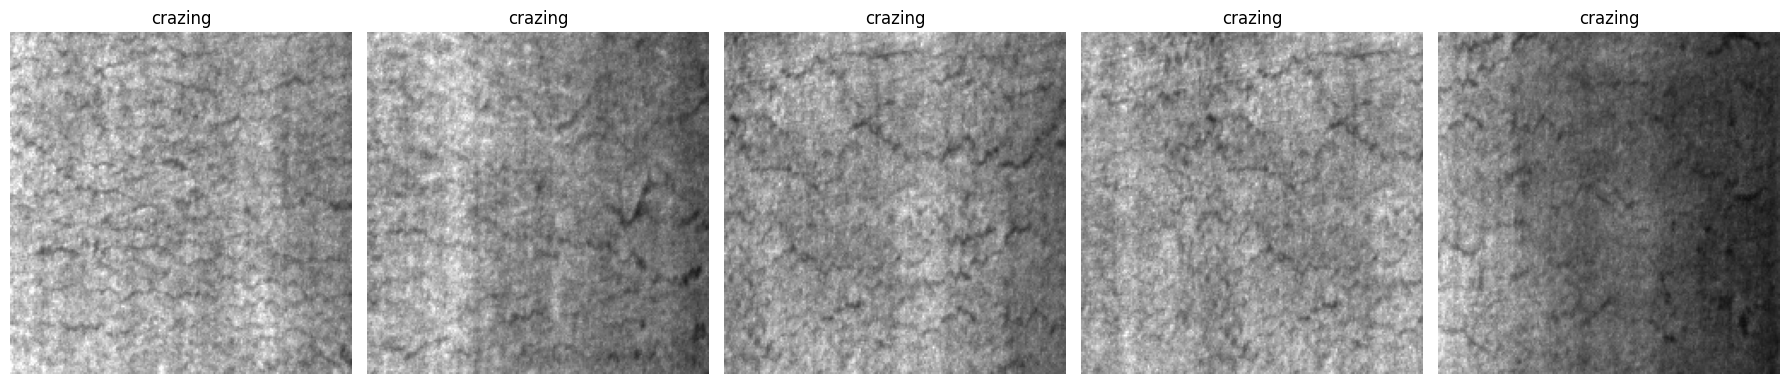

In [3]:
if not train_image_paths:
    raise ValueError("No training images found. Check the dataset path.")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, path in zip(axes, train_image_paths[:5]):
    image = cv2.imread(str(path))

    if image is None:
        ax.set_title("Unreadable image")
        ax.axis("off")
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image_rgb)
    ax.set_title(path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
image = cv2.imread(str(train_image_paths[0]))

if image is None:
    raise ValueError("Could not read the selected image.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image shape:", image.shape)
print("Grayscale shape:", gray.shape)
print("Data type:", gray.dtype)
print("Minimum intensity:", gray.min())
print("Maximum intensity:", gray.max())

print("\nFirst 5 x 5 grayscale pixel values:")
print(gray[:5, :5])

Image shape: (200, 200, 3)
Grayscale shape: (200, 200)
Data type: uint8
Minimum intensity: 60
Maximum intensity: 255

First 5 x 5 grayscale pixel values:
[[185 175 171 198 190]
 [169 171 195 196 189]
 [192 222 200 223 225]
 [188 198 211 197 227]
 [177 194 200 242 240]]


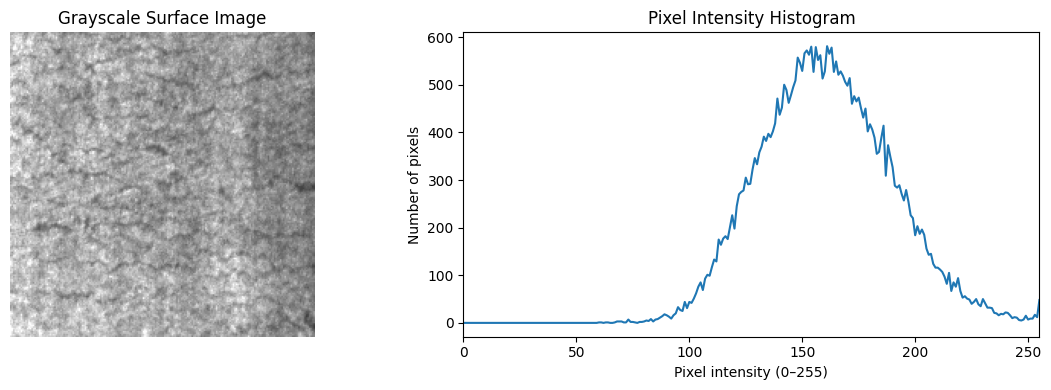

In [5]:

# Select one image from the training dataset
image_path = train_image_paths[0]

image = cv2.imread(str(image_path))
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Calculate the grayscale histogram
histogram = cv2.calcHist(
    [gray],
    [0],
    None,
    [256],
    [0, 256]
)

# Display image and histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale Surface Image")
axes[0].axis("off")

axes[1].plot(histogram)
axes[1].set_title("Pixel Intensity Histogram")
axes[1].set_xlabel("Pixel intensity (0–255)")
axes[1].set_ylabel("Number of pixels")
axes[1].set_xlim(0, 255)

plt.tight_layout()
plt.show()


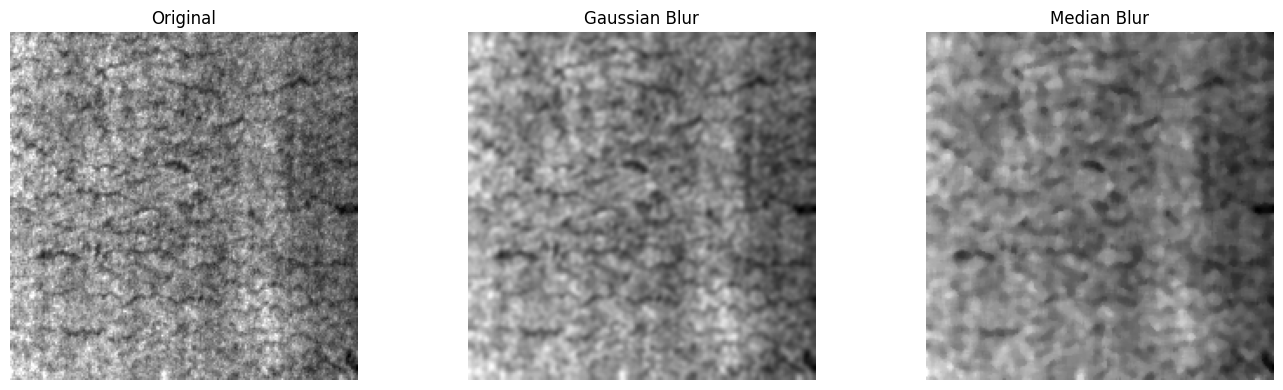

In [6]:

# Gaussian filtering: smooth intensity changes
gaussian = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# Median filtering: replace pixels using neighborhood medians
median = cv2.medianBlur(
    gray,
    5
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(gaussian, cmap="gray")
axes[1].set_title("Gaussian Blur")
axes[1].axis("off")

axes[2].imshow(median, cmap="gray")
axes[2].set_title("Median Blur")
axes[2].axis("off")

plt.tight_layout()
plt.show()


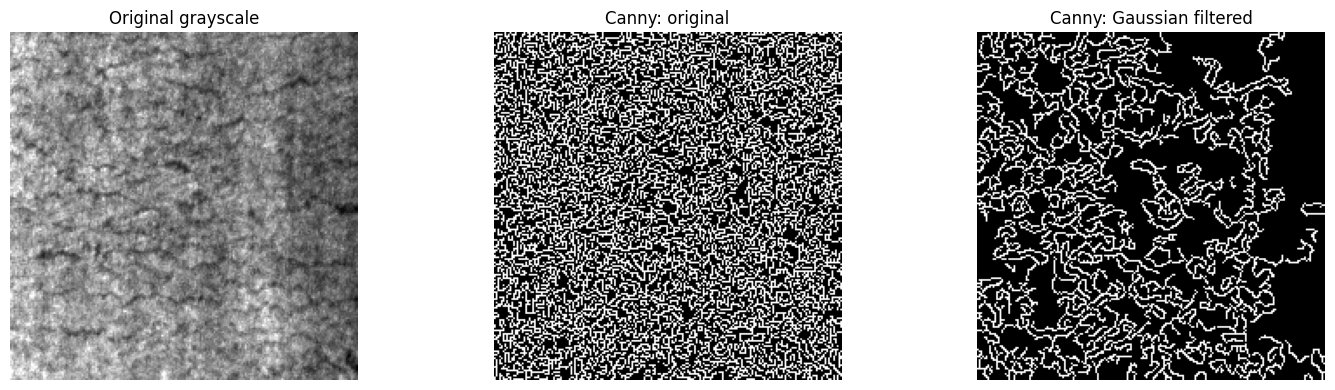

Edge pixel percentage before filtering: 37.87 %
Edge pixel percentage after filtering: 19.1 %


In [7]:

# Apply Canny edge detection to the original grayscale image
edges_original = cv2.Canny(gray, 50, 150)

# Apply Canny after Gaussian smoothing
edges_gaussian = cv2.Canny(gaussian, 50, 150)

# Compare the results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original grayscale")
axes[0].axis("off")

axes[1].imshow(edges_original, cmap="gray")
axes[1].set_title("Canny: original")
axes[1].axis("off")

axes[2].imshow(edges_gaussian, cmap="gray")
axes[2].set_title("Canny: Gaussian filtered")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print(
    "Edge pixel percentage before filtering:",
    round(100 * np.mean(edges_original > 0), 2), "%"
)

print(
    "Edge pixel percentage after filtering:",
    round(100 * np.mean(edges_gaussian > 0), 2), "%"
)


Otsu threshold value: 162.0


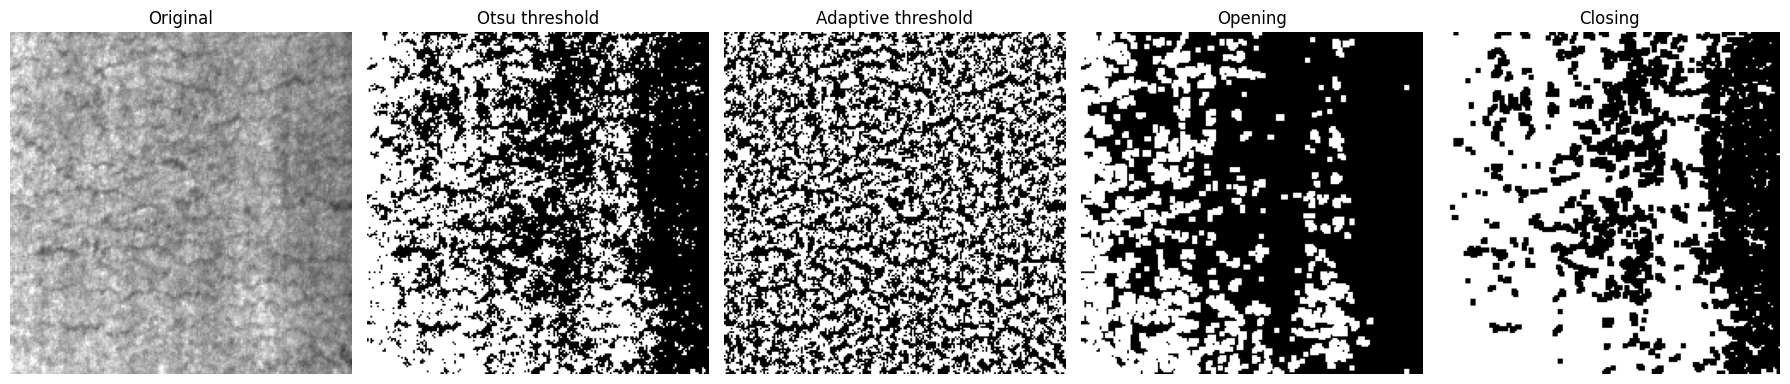

In [8]:

# Experiment 1: Otsu thresholding
threshold_value, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Experiment 2: Adaptive thresholding
adaptive = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    3
)

# Experiment 3: Morphological opening
kernel = np.ones((3, 3), np.uint8)

opened = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel
)

# Experiment 4: Morphological closing
closed = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)

print("Otsu threshold value:", threshold_value)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

results = [
    ("Original", gray),
    ("Otsu threshold", binary),
    ("Adaptive threshold", adaptive),
    ("Opening", opened),
    ("Closing", closed),
]

for ax, (title, result) in zip(axes, results):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:

from pathlib import Path

DATA_DIR = Path("../data/raw/NEU-DET")

for split in ["train", "validation"]:
    annotation_dir = DATA_DIR / split / "annotations"

    print(f"\n--- {split.upper()} ---")
    print("Directory exists:", annotation_dir.exists())

    if annotation_dir.exists():
        files = sorted(
            p for p in annotation_dir.rglob("*")
            if p.is_file()
        )

        print("Total annotation files:", len(files))

        for path in files[:10]:
            print(
                "Name:", path.name,
                "| Extension:", path.suffix
            )



--- TRAIN ---
Directory exists: True
Total annotation files: 1439
Name: crazing_1.xml | Extension: .xml
Name: crazing_10.xml | Extension: .xml
Name: crazing_100.xml | Extension: .xml
Name: crazing_101.xml | Extension: .xml
Name: crazing_102.xml | Extension: .xml
Name: crazing_103.xml | Extension: .xml
Name: crazing_104.xml | Extension: .xml
Name: crazing_105.xml | Extension: .xml
Name: crazing_106.xml | Extension: .xml
Name: crazing_107.xml | Extension: .xml

--- VALIDATION ---
Directory exists: True
Total annotation files: 361
Name: crazing_240.xml | Extension: .xml
Name: crazing_241.xml | Extension: .xml
Name: crazing_242.xml | Extension: .xml
Name: crazing_243.xml | Extension: .xml
Name: crazing_244.xml | Extension: .xml
Name: crazing_245.xml | Extension: .xml
Name: crazing_246.xml | Extension: .xml
Name: crazing_247.xml | Extension: .xml
Name: crazing_248.xml | Extension: .xml
Name: crazing_249.xml | Extension: .xml


In [10]:

annotation_dir = DATA_DIR / "train" / "annotations"

annotation_files = sorted(
    p for p in annotation_dir.rglob("*")
    if p.is_file()
)

if annotation_files:
    sample = annotation_files[0]

    print("Sample file:", sample.name)

    if sample.suffix.lower() in {".xml", ".txt", ".json", ".csv"}:
        print(sample.read_text(encoding="utf-8")[:3000])
    else:
        print("This format needs a suitable file reader.")
else:
    print("No annotation files found in the training directory.")


Sample file: crazing_1.xml
<annotation>
	<folder>cr</folder>
	<filename>crazing_1.jpg</filename>
	<source>
		<database>NEU-DET</database>
	</source>
	<size>
		<width>200</width>
		<height>200</height>
		<depth>1</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>crazing</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>2</xmin>
			<ymin>2</ymin>
			<xmax>193</xmax>
			<ymax>194</ymax>
		</bndbox>
	</object>
</annotation>

